# Transformation of density matrix from one basis set to another
**Author:** Egor Trushin  
**Date created:** 04/06/2025  
**Last modified:** 13/08/2025

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pyscf import scf, gto, dft
from pyscf.scf.addons import project_dm_nr2nr

In [2]:
npts = 20000
zcoords = np.linspace(-15, 15, npts)[:,None]
ycoords = np.zeros(npts)[:,None]
xcoords = np.zeros(npts)[:,None]
coords = np.concatenate((xcoords, ycoords, zcoords), axis=-1)

## aug-cc-pVTZ $\rightarrow$ aug-cc-pVQZ

In [3]:
mol1 = gto.M(atom="C 0. 0. -0.646514; O 0. 0. 0.484886", basis="aug-cc-pVTZ")
mol1.verbose = 0
mol1.symmetry = False

mol2 = gto.M(atom="C 0. 0. -0.646514; O 0. 0. 0.484886", basis="aug-cc-pVQZ")
mol2.verbose = 0
mol2.symmetry = False

mf = scf.RHF(mol1).density_fit().run()

dm1 = mf.make_rdm1()
dm2 = project_dm_nr2nr(mol1, dm1, mol2)
print("Size of original density matrix:", dm1.shape)
print("Size of new density matrix:", dm2.shape)

ao1 = dft.numint.eval_ao(mol1, coords)
den1 = dft.numint.eval_rho(mol1, ao1, dm1)
ao2 = dft.numint.eval_ao(mol2, coords)
den2 = dft.numint.eval_rho(mol2, ao2, dm2)

Size of original density matrix: (92, 92)
Size of new density matrix: (160, 160)


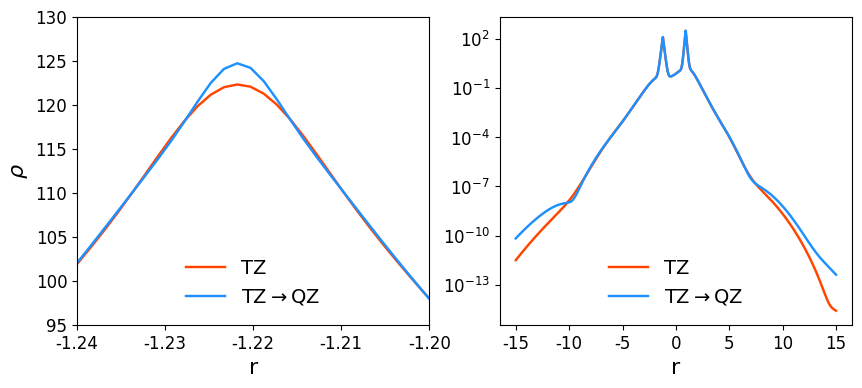

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.))

axs[0].plot(zcoords, den1, color="orangered", label="TZ")
axs[0].plot(zcoords, den2, color="dodgerblue", label="TZ$\\rightarrow$QZ")
axs[0].set_ylim(95, 130)
axs[0].set_xlim(-1.24, -1.2)
axs[0].set_ylabel("$\\rho$")
axs[0].set_xlabel("r")
axs[0].legend(frameon=False)

axs[1].plot(zcoords, den1, color="orangered", label="TZ")
axs[1].plot(zcoords, den2, color="dodgerblue", label="TZ$\\rightarrow$QZ")
axs[1].set_yscale("log")
axs[1].set_xlabel("r")
axs[1].legend(frameon=False)

plt.show()

## aug-cc-pVQZ $\rightarrow$ aug-cc-pV5Z

In [5]:
mol1 = gto.M(atom="C 0. 0. -0.646514; O 0. 0. 0.484886", basis="aug-cc-pVQZ")
mol1.verbose = 0
mol1.symmetry = False

mol2 = gto.M(atom="C 0. 0. -0.646514; O 0. 0. 0.484886", basis="aug-cc-pV5Z")
mol2.verbose = 0
mol2.symmetry = False

mf = scf.RHF(mol1).density_fit().run()

dm1 = mf.make_rdm1()
dm2 = project_dm_nr2nr(mol1, dm1, mol2)
print("Size of original density matrix:", dm1.shape)
print("Size of new density matrix:", dm2.shape)

ao1 = dft.numint.eval_ao(mol1, coords)
den1 = dft.numint.eval_rho(mol1, ao1, dm1)
ao2 = dft.numint.eval_ao(mol2, coords)
den2 = dft.numint.eval_rho(mol2, ao2, dm2)

Size of original density matrix: (160, 160)
Size of new density matrix: (254, 254)


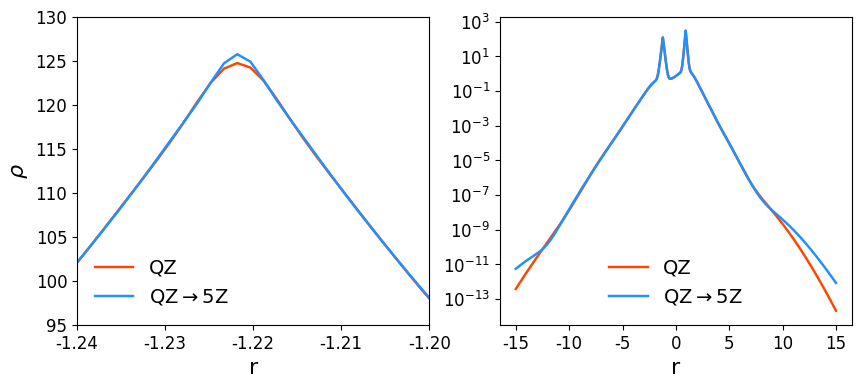

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.))

axs[0].plot(zcoords, den1, color="orangered", label="QZ")
axs[0].plot(zcoords, den2, color="dodgerblue", label="QZ$\\rightarrow$5Z")
axs[0].set_ylim(95, 130)
axs[0].set_xlim(-1.24, -1.2)
axs[0].set_ylabel("$\\rho$")
axs[0].set_xlabel("r")
axs[0].legend(frameon=False)

axs[1].plot(zcoords, den1, color="orangered", label="QZ")
axs[1].plot(zcoords, den2, color="dodgerblue", label="QZ$\\rightarrow$5Z")
axs[1].set_yscale("log")
axs[1].set_xlabel("r")
axs[1].legend(frameon=False)

plt.show()

## QZ and QZ $\rightarrow$ 5Z versus 5Z

In [7]:
mol3 = gto.M(atom="C 0. 0. -0.646514; O 0. 0. 0.484886", basis="aug-cc-pV5Z")
mol3.verbose = 0
mol3.symmetry = False

mf = scf.RHF(mol3).density_fit().run()

dm3 = mf.make_rdm1()

ao3 = dft.numint.eval_ao(mol3, coords)
den3 = dft.numint.eval_rho(mol3, ao3, dm3)

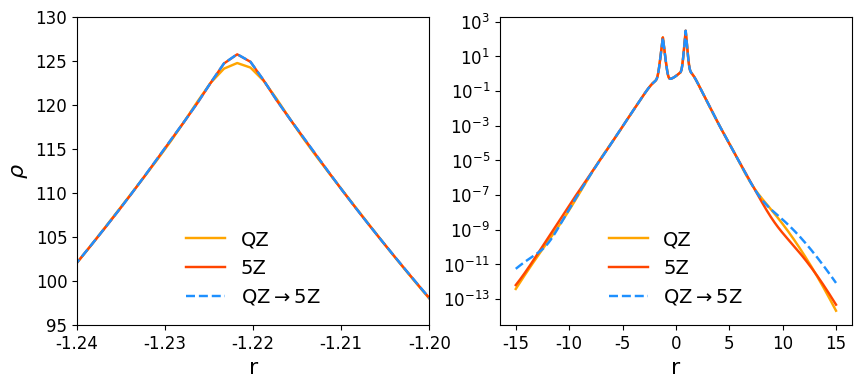

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.))

axs[0].plot(zcoords, den1, color="orange", label="QZ")
axs[0].plot(zcoords, den3, color="orangered", label="5Z")
axs[0].plot(zcoords, den2, "--", color="dodgerblue", label="QZ$\\rightarrow$5Z")
axs[0].set_ylim(95, 130)
axs[0].set_xlim(-1.24, -1.2)
axs[0].set_ylabel("$\\rho$")
axs[0].set_xlabel("r")
axs[0].legend(frameon=False)

axs[1].plot(zcoords, den1, color="orange", label="QZ")
axs[1].plot(zcoords, den3, color="orangered", label="5Z")
axs[1].plot(zcoords, den2, "--", color="dodgerblue", label="QZ$\\rightarrow$5Z")
axs[1].set_yscale("log")
axs[1].set_xlabel("r")
axs[1].legend(frameon=False)

plt.show()